# Лабораторная работа 3. Decoder-only Transformer (GPT)

Источник: `materials/Лаб3.md`. Архитектура decoder-only / CLM — лекция `materials/notes/disciplines__nlp__lectures__bert-gpt-2.md`. Positional encoding, masked self-attention, FFN, Residual+LN — `materials/notes/disciplines__nlp__lectures__transformer-2.md`.

Решения по Карте ЛР 3: схема **B (causal LM)**; TinyStories **subset**; без `torch.nn.Transformer*` / Encoder / cross-attention.


## 1. Датасет Tiny Stories

Пункт 1 (`Лаб3.md`). Train/valid с Hugging Face. Полный train большой — берём урезанный subset (кэш вне OneDrive). Можно заменить другим текстовым корпусом.


In [1]:
import math
import re
import urllib.request
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset

DEVICE = torch.device('cpu')
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# Вне курса: кэш вне OneDrive (INDEX: полные TinyStories в репо не кладём)
CACHE = Path.home() / '.cache' / 'studies2026-nlp' / 'tinystories'
CACHE.mkdir(parents=True, exist_ok=True)
TRAIN_URL = 'https://huggingface.co/datasets/roneneldan/TinyStories/resolve/main/TinyStories-train.txt'
VALID_URL = 'https://huggingface.co/datasets/roneneldan/TinyStories/resolve/main/TinyStories-valid.txt'
TRAIN_PATH = CACHE / 'TinyStories-train-subset.txt'
VALID_PATH = CACHE / 'TinyStories-valid.txt'
VALID_SUBSET_PATH = CACHE / 'TinyStories-valid-subset.txt'

TRAIN_STORIES = 3000
VALID_STORIES = 400
MAX_SEQ_LEN = 64
VOCAB_SIZE = 5000
EMBED_DIM = 128
NUM_HEADS = 2  # Лаб3: можно 1 голову; 2 — упрощённый MHA
NUM_LAYERS = 2
FF_DIM = 256
BATCH_SIZE = 32
EPOCHS = 3
LR = 3e-4
PAD, UNK, BOS, EOS = '<pad>', '<unk>', '<bos>', '<eos>'


def download(url: str, path: Path) -> None:
    if path.exists() and path.stat().st_size > 0:
        return
    print('download', url, '->', path)
    urllib.request.urlretrieve(url, path)


def stream_train_subset(url: str, path: Path, n_stories: int) -> None:
    if path.exists() and path.stat().st_size > 0:
        return
    print('stream subset', n_stories, '->', path)
    with urllib.request.urlopen(url) as resp, path.open('w', encoding='utf-8') as out:
        count = 0
        for raw in resp:
            line = raw.decode('utf-8', errors='replace').strip()
            line = line.replace('<|endoftext|>', ' ').strip()
            if not line:
                continue
            out.write(line + '\n')
            count += 1
            if count >= n_stories:
                break


def load_stories(path: Path, limit: int | None = None) -> list[str]:
    stories = []
    with path.open(encoding='utf-8', errors='replace') as f:
        for line in f:
            text = line.replace('<|endoftext|>', ' ').strip()
            if text:
                stories.append(text)
            if limit is not None and len(stories) >= limit:
                break
    return stories


download(VALID_URL, VALID_PATH)
stream_train_subset(TRAIN_URL, TRAIN_PATH, TRAIN_STORIES)
if not VALID_SUBSET_PATH.exists():
    vs = load_stories(VALID_PATH, VALID_STORIES)
    VALID_SUBSET_PATH.write_text('\n'.join(vs) + '\n', encoding='utf-8')

train_stories = load_stories(TRAIN_PATH, TRAIN_STORIES)
valid_stories = load_stories(VALID_SUBSET_PATH, VALID_STORIES)
print('train stories:', len(train_stories), 'valid stories:', len(valid_stories))
print('пример:', train_stories[0][:180], '...')


train stories: 3000 valid stories: 400
пример: One day, a little girl named Lily found a needle in her room. She knew it was difficult to play with it because it was sharp. Lily wanted to share the needle with her mom, so she c ...


## 2. Токенизация, нумерация и разделение на начало/конец

Пункт 2 (`Лаб3.md`). Токенизация пробельная (допустимы «любые инструменты»). Словарь — только на train. Разделение начало/конец: ниже — демо на нескольких примерах; полный `split_start_end` используется на инференсе (§5) как промпт. **Обучение — схема B (CLM)** по всей последовательности (bert-gpt-2), не пара «начало→конец».


In [2]:
def tokenize(text: str) -> list[str]:
    text = text.lower()
    text = re.sub(r'[^a-z0-9\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text.split() if text else []


train_tokens = [tokenize(s) for s in train_stories]
valid_tokens = [tokenize(s) for s in valid_stories]
train_tokens = [t for t in train_tokens if len(t) >= 4]
valid_tokens = [t for t in valid_tokens if len(t) >= 4]

# п.2: начало / конец (поровну) — для отчёта и промпта на инференсе
starts, ends = [], []
for toks in train_tokens[:5]:
    mid = max(1, len(toks) // 2)
    starts.append(toks[:mid])
    ends.append(toks[mid:])
print('пример начало:', starts[0][:12])
print('пример конец:', ends[0][:12])

counter = Counter(tok for toks in train_tokens for tok in toks)
vocab = {PAD: 0, UNK: 1, BOS: 2, EOS: 3}
for word, _ in counter.most_common(VOCAB_SIZE - len(vocab)):
    if word not in vocab:
        vocab[word] = len(vocab)
itos = {i: t for t, i in vocab.items()}
print('vocab:', len(vocab))


def encode(tokens: list[str], max_len: int = MAX_SEQ_LEN) -> tuple[list[int], int]:
    ids = [vocab.get(t, vocab[UNK]) for t in tokens][: max_len - 2]
    ids = [vocab[BOS]] + ids + [vocab[EOS]]
    length = len(ids)
    if len(ids) < max_len:
        ids = ids + [vocab[PAD]] * (max_len - len(ids))
    return ids, length


def split_start_end(tokens: list[str]) -> tuple[list[str], list[str]]:
    mid = max(1, len(tokens) // 2)
    return tokens[:mid], tokens[mid:]


пример начало: ['one', 'day', 'a', 'little', 'girl', 'named', 'lily', 'found', 'a', 'needle', 'in', 'her']
пример конец: ['because', 'it', 'was', 'sharp', 'lily', 'wanted', 'to', 'share', 'the', 'needle', 'with', 'her']
vocab: 3661


## 3. Padding и батчи

Пункт 3 (`Лаб3.md`). Все последовательности одной длины `MAX_SEQ_LEN`; DataLoader с батчами.


In [3]:
class StoryLMDataset(Dataset):
    def __init__(self, tokenized: list[list[str]]):
        self.samples = []
        for toks in tokenized:
            ids, length = encode(toks)
            self.samples.append((ids, length))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        ids, length = self.samples[idx]
        x = torch.tensor(ids[:-1], dtype=torch.long)
        y = torch.tensor(ids[1:], dtype=torch.long)
        return x, y, min(length - 1, MAX_SEQ_LEN - 1)


train_ds = StoryLMDataset(train_tokens)
valid_ds = StoryLMDataset(valid_tokens)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
valid_loader = DataLoader(valid_ds, batch_size=BATCH_SIZE, shuffle=False)
print('train batches:', len(train_loader), 'seq_len input:', MAX_SEQ_LEN - 1)
xb, yb, lb = next(iter(train_loader))
print('batch', tuple(xb.shape), tuple(yb.shape), lb[:5].tolist())


train batches: 93 seq_len input: 63
batch (32, 63) (32, 63) [49, 38, 39, 24, 51]


## 4. Decoder-only модель (GPT)

Пункт 4 (`Лаб3.md`). Стек декодер-блоков **без Encoder и без cross-attention**. В блоке: masked self-attention, FFN, Residual, LayerNorm (лекция transformer-2). Готовый `torch.nn.Transformer*` не используем.

Порядок LN: в коде **pre-LN** (нормализация до Attention/FFN). На схемах transformer-2 чаще post-LN (после residual). Pre-LN выбран как устойчивый вариант для короткого обучения с нуля (общие знания / практика GPT-подобных моделей); состав блока тот же, что в лекции.


In [4]:
def sinusoidal_positional_encoding(max_len: int, d_model: int) -> torch.Tensor:
    # лекция transformer-2: PE(pos, 2i)=sin, PE(pos, 2i+1)=cos
    pe = torch.zeros(max_len, d_model)
    position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
    div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
    pe[:, 0::2] = torch.sin(position * div_term)
    pe[:, 1::2] = torch.cos(position * div_term)
    return pe


def causal_attn_mask(size: int, device) -> torch.Tensor:
    # MultiheadAttention: True = позиция запрещена (доки PyTorch)
    return torch.triu(torch.ones(size, size, dtype=torch.bool, device=device), diagonal=1)


class DecoderBlock(nn.Module):
    def __init__(self, d_model, n_heads, ff_dim, dropout=0.1):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = nn.MultiheadAttention(d_model, n_heads, dropout=dropout, batch_first=True)
        self.ln2 = nn.LayerNorm(d_model)
        self.ff = nn.Sequential(
            nn.Linear(d_model, ff_dim),
            nn.ReLU(),
            nn.Linear(ff_dim, d_model),
        )
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, attn_mask, key_padding_mask):
        # Residual+LN — transformer-2; pre-LN — удобная практика (доки / общие знания)
        h = self.ln1(x)
        attn_out, _ = self.attn(
            h, h, h,
            attn_mask=attn_mask,
            key_padding_mask=key_padding_mask,
            need_weights=False,
        )
        x = x + self.dropout(attn_out)
        h = self.ln2(x)
        x = x + self.dropout(self.ff(h))
        return x


class MiniGPT(nn.Module):
    # decoder-only GPT: Embedding + PE + N×DecoderBlock + LM-head
    def __init__(self, vocab_size, d_model, n_heads, n_layers, ff_dim, max_len):
        super().__init__()
        self.tok = nn.Embedding(vocab_size, d_model, padding_idx=0)
        self.register_buffer('pe', sinusoidal_positional_encoding(max_len, d_model), persistent=False)
        self.blocks = nn.ModuleList(
            [DecoderBlock(d_model, n_heads, ff_dim) for _ in range(n_layers)]
        )
        self.ln_f = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size, bias=False)

    def forward(self, x, lengths):
        b, t = x.shape
        h = self.tok(x) + self.pe[:t].unsqueeze(0)
        attn_mask = causal_attn_mask(t, x.device)
        arange = torch.arange(t, device=x.device).unsqueeze(0)
        key_padding_mask = arange >= lengths.unsqueeze(1)
        for block in self.blocks:
            h = block(h, attn_mask, key_padding_mask)
        h = self.ln_f(h)
        return self.head(h)


model = MiniGPT(len(vocab), EMBED_DIM, NUM_HEADS, NUM_LAYERS, FF_DIM, MAX_SEQ_LEN).to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
print('params:', n_params)
print('запрет соблюдён: нет nn.Transformer* / Encoder / cross-attention')


params: 1202432
запрет соблюдён: нет nn.Transformer* / Encoder / cross-attention


## 5. Обучение и инференс

Пункт 5 (`Лаб3.md`). Критерий: обучение без ошибок; качество не оцениваем. Инференс: начало истории (первая половина) → генерация продолжения; плюс свои промпты.


epoch 1/3 train_loss=6.7289 valid_loss=5.8995


epoch 2/3 train_loss=5.6451 valid_loss=5.4185


epoch 3/3 train_loss=5.2458 valid_loss=5.0993


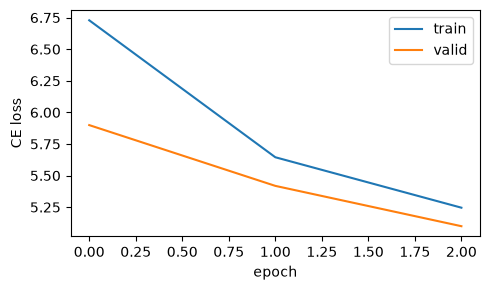

In [5]:
criterion = nn.CrossEntropyLoss(ignore_index=vocab[PAD])
optimizer = torch.optim.Adam(model.parameters(), lr=LR)


def train_epoch(model, loader):
    model.train()
    total, n = 0.0, 0
    for xb, yb, lengths in loader:
        xb, yb, lengths = xb.to(DEVICE), yb.to(DEVICE), lengths.to(DEVICE)
        optimizer.zero_grad()
        logits = model(xb, lengths)
        loss = criterion(logits.reshape(-1, logits.size(-1)), yb.reshape(-1))
        loss.backward()
        optimizer.step()
        total += loss.item() * len(xb)
        n += len(xb)
    return total / max(n, 1)


@torch.no_grad()
def eval_loss(model, loader):
    model.eval()
    total, n = 0.0, 0
    for xb, yb, lengths in loader:
        xb, yb, lengths = xb.to(DEVICE), yb.to(DEVICE), lengths.to(DEVICE)
        logits = model(xb, lengths)
        loss = criterion(logits.reshape(-1, logits.size(-1)), yb.reshape(-1))
        total += loss.item() * len(xb)
        n += len(xb)
    return total / max(n, 1)


history = []
for epoch in range(1, EPOCHS + 1):
    tr = train_epoch(model, train_loader)
    va = eval_loss(model, valid_loader)
    history.append((tr, va))
    print(f'epoch {epoch}/{EPOCHS} train_loss={tr:.4f} valid_loss={va:.4f}')

plt.figure(figsize=(5, 3))
plt.plot([h[0] for h in history], label='train')
plt.plot([h[1] for h in history], label='valid')
plt.xlabel('epoch')
plt.ylabel('CE loss')
plt.legend()
plt.tight_layout()
plt.show()


In [6]:
@torch.no_grad()
def generate(model, prompt_tokens: list[str], max_new: int = 40) -> str:
    model.eval()
    ids, length = encode(prompt_tokens, max_len=MAX_SEQ_LEN)
    cur = torch.tensor([ids[:length]], dtype=torch.long, device=DEVICE)
    if cur[0, -1].item() == vocab[EOS]:
        cur = cur[:, :-1]
    for _ in range(max_new):
        if cur.size(1) >= MAX_SEQ_LEN - 1:
            break
        lengths = torch.tensor([cur.size(1)], device=DEVICE)
        logits = model(cur, lengths)
        next_id = int(logits[0, -1].argmax())
        if next_id in (vocab[EOS], vocab[PAD]):
            break
        cur = torch.cat([cur, torch.tensor([[next_id]], device=DEVICE)], dim=1)
    out_ids = cur[0].tolist()
    words = [itos.get(i, UNK) for i in out_ids if i not in (vocab[PAD], vocab[BOS])]
    return ' '.join(words)


print('=== инференс на valid (начало → продолжение) ===')
for i, toks in enumerate(valid_tokens[:3]):
    start, end = split_start_end(toks)
    gen = generate(model, start, max_new=30)
    print(f'\n[{i}] prompt:', ' '.join(start[:20]), '...')
    print('gold end:', ' '.join(end[:20]), '...')
    print('generated:', gen)

print('\n=== свои истории ===')
for prompt in [
    'once upon a time there was a little girl',
    'the dog ran to the park and',
]:
    print('prompt:', prompt)
    print('gen:', generate(model, tokenize(prompt), max_new=35))
    print()


=== инференс на valid (начало → продолжение) ===

[0] prompt: spot spot saw the shiny car and said wow kitty your car is so ...
gold end: bright and clean kitty smiled and replied thank you spot i polish it every day ...
generated: spot spot saw the shiny car and said wow kitty your car is so happy and said that the little girl and said

[1] prompt: after playing with the car kitty and spot felt thirsty they found a small pond with clear ...
gold end: water they drank the water and felt very happy they played together all day and became best friends ...
generated: after playing with the car kitty and spot felt thirsty they found a small pond with clear and said

[2] prompt: once upon a time in a big forest there lived a rhinoceros named roxy roxy loved to climb she climbed ...
gold end: day roxy found an icy hill she had never seen anything like it before it was shiny and cold and ...
generated: once upon a time in a big forest there lived a rhinoceros named <unk> <unk> loved to climb 